**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación · CICESE  
M.C. Joan Manuel Raygoza Romero

# ICD 24 · Transformers y predicción del siguiente token

Sesión 24 del curso. Diapositivas: [icd-24-transformers.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-24-transformers.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-24-transformers.ipynb)

Seguiremos el recorrido de la presentación desde los tokens hasta las probabilidades del vocabulario. Inspeccionaremos los cálculos de una cabeza, entrenaremos un mini-GPT con frases cortas y probaremos un modelo preentrenado de Hugging Face.

| Bloque | Pregunta | Qué observarás |
|---|---|---|
| 1. Autoatención | ¿Cómo decide cuánto aporta cada token? | Productos punto, pesos y una suma ponderada |
| 2. Máscara causal | ¿Qué posiciones puede consultar un decodificador? | Dos mapas de atención y una prueba de fuga de información |
| 3. Mini-GPT | ¿Cómo se aprende y se usa la predicción del siguiente token? | Pérdida, probabilidades, dos cabezas y texto generado |
| 4. LLM preentrenado | ¿Cómo pasa un modelo de lenguaje de una instrucción a una respuesta? | Subpalabras, probabilidades y generación en español |

Ejecuta las celdas en orden. Los tres primeros bloques forman el recorrido principal y el cuarto es una extensión. Puedes correrlo en Jupyter o Colab con **NumPy, Matplotlib y TensorFlow/Keras**. En un entorno vacío, ejecuta `%pip install "tensorflow>=2.16" numpy matplotlib` y reinicia el kernel. Los datos de entrenamiento se generan en el notebook. La sección 4 usa PyTorch y descarga los pesos de Qwen la primera vez.

In [1]:
import os

#os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
#os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "4")
#os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")

import re
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import Markdown, display
from tensorflow import keras
from tensorflow.keras import layers

SEMILLA = 24
keras.utils.set_random_seed(SEMILLA)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
VERDE, NARANJA = "#087f79", "#b8562c"

## 1. Una cabeza de autoatención con NumPy

Tomemos cuatro tokens de «El gato duerme.» y supongamos que ya proyectamos sus vectores de entrada con $W_Q$, $W_K$ y $W_V$. En este ejemplo fijamos a mano los vectores proyectados para poder seguir el cálculo. Cada fila de $Q$, $K$ y $V$ corresponde a un token y tiene dos componentes.

$$
S=\frac{QK^\top}{\sqrt{d_k}}, \qquad
A=\operatorname{softmax}_{\text{por fila}}(S), \qquad
Z=AV.
$$

Para actualizar **gato**, tomamos su *query* y la comparamos con las cuatro *keys*. Los cuatro pesos resultantes suman uno. Cada peso multiplica el *value* del token correspondiente. Vamos a modificar únicamente la *key* de **duerme** para ver cómo se redistribuyen los pesos.

Query de «gato»             [1. 0.]
Puntajes escalados          [-0.283  0.495  1.202 -0.424]
Pesos antes                 [0.118 0.257 0.522 0.103]
Pesos con la key modificada [0.225 0.49  0.09  0.195]
Salida antes y después      [0.225 0.76 ] [0.338 0.272]


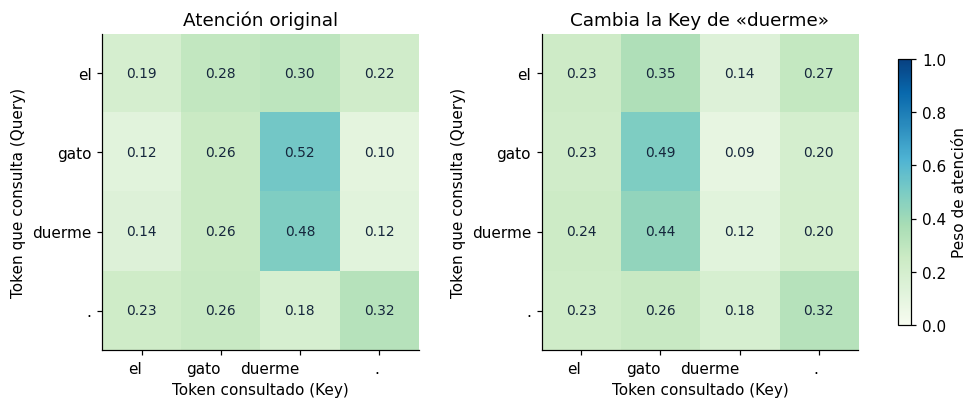

In [2]:
tokens_demo = ["el", "gato", "duerme", "."]
Q = np.array([[0.4, 0.6], [1.0, 0.0], [0.8, -0.2], [0.0, 1.0]])
K = np.array([[-0.4, 0.1], [0.7, 0.3], [1.7, -0.2], [-0.6, 0.6]])
V = np.array([[0.2, 0.3], [0.7, 0.1], [0.1, 1.3], [-0.3, 0.2]])

def softmax_filas(puntajes):
    centrados = puntajes - np.max(puntajes, axis=-1, keepdims=True)
    exp = np.exp(centrados)
    return exp / exp.sum(axis=-1, keepdims=True)

def atencion_numpy(q, k, v, causal=False):
    puntajes = q @ k.T / np.sqrt(q.shape[-1])
    if causal:
        permitidos = np.tri(len(q), len(k), dtype=bool)
        puntajes = np.where(permitidos, puntajes, -np.inf)
    pesos = softmax_filas(puntajes)
    return puntajes, pesos, pesos @ v

def mapa_atencion(ax, pesos, tokens, titulo, anotar=True):
    mapa = ax.imshow(pesos, cmap="GnBu", vmin=0, vmax=1)
    posiciones = np.arange(len(tokens))
    ax.set(xticks=posiciones, yticks=posiciones, xlabel="Token consultado (Key)",
           ylabel="Token que consulta (Query)", title=titulo)
    ax.set_xticklabels(tokens, rotation=35 if len(tokens) > 5 else 0, ha="right")
    ax.set_yticklabels(tokens)
    if anotar:
        for i, j in np.ndindex(pesos.shape):
            color = "white" if pesos[i, j] > 0.58 else "#15263c"
            ax.text(j, i, f"{pesos[i, j]:.2f}", color=color,
                    ha="center", va="center", fontsize=9)
    return mapa

puntajes, pesos, salida = atencion_numpy(Q, K, V)
k_alternativa = K.copy()
k_alternativa[2, 0] = -1.7
_, pesos_nuevos, salida_nueva = atencion_numpy(Q, k_alternativa, V)

print("Query de «gato»            ", Q[1])
print("Puntajes escalados         ", puntajes[1])
print("Pesos antes                ", pesos[1])
print("Pesos con la key modificada", pesos_nuevos[1])
print("Salida antes y después     ", salida[1], salida_nueva[1])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
mapa_atencion(axs[0], pesos, tokens_demo, "Atención original")
mapa = mapa_atencion(axs[1], pesos_nuevos, tokens_demo, "Cambia la Key de «duerme»")
fig.colorbar(mapa, ax=axs, shrink=0.84, label="Peso de atención")
plt.show()

## 2. Máscara causal y objetivo desplazado

Para entrenar un GPT, cada posición predice el token **siguiente**. Alineamos las entradas y los objetivos desplazando el texto un lugar.

| Posición | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| Entrada | el | gato | duerme | . |
| Objetivo | gato | duerme | . | `<fin>` |

La posición 1 recibe **gato** y debe predecir **duerme**. Como **duerme** está en la posición 2 de la entrada completa, debemos bloquear esa columna para esa consulta. Lo hacemos asignando $-\infty$ a los puntajes con $j>i$ antes del *softmax*. El token actual sigue disponible.

Durante el entrenamiento, las entradas están disponibles juntas y podemos calcular todas las filas en una pasada. La máscara restringe la información de cada predicción. En el ejemplo de abajo cambiamos drásticamente el *value* de un token futuro para comprobar qué sale de la fila de **gato**.

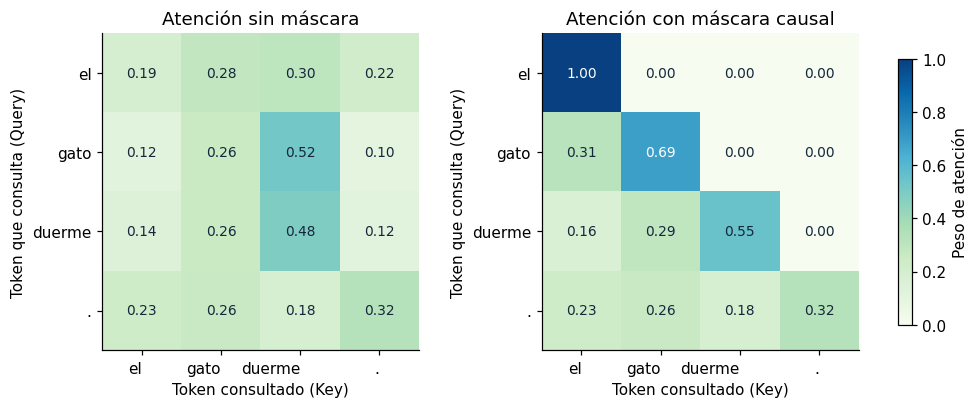

Salida para «gato» después de cambiar un token futuro
Sin máscara     [0.225 0.76 ] → [ 5.392 -5.137]
Con máscara     [0.543 0.163] → [0.543 0.163]


In [3]:
_, pesos_causales, salida_causal = atencion_numpy(Q, K, V, causal=True)

v_futuro = V.copy()
v_futuro[2] = [10.0, -10.0]
_, _, salida_abierta_cambio = atencion_numpy(Q, K, v_futuro)
_, _, salida_causal_cambio = atencion_numpy(Q, K, v_futuro, causal=True)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
mapa_atencion(axs[0], pesos, tokens_demo, "Atención sin máscara")
mapa = mapa_atencion(axs[1], pesos_causales, tokens_demo, "Atención con máscara causal")
fig.colorbar(mapa, ax=axs, shrink=0.84, label="Peso de atención")
plt.show()

print("Salida para «gato» después de cambiar un token futuro")
print(f"Sin máscara     {salida[1]} → {salida_abierta_cambio[1]}")
print(f"Con máscara     {salida_causal[1]} → {salida_causal_cambio[1]}")
assert np.all(pesos_causales[np.triu_indices(len(Q), k=1)] == 0)
assert np.allclose(pesos_causales.sum(axis=1), 1)
assert np.allclose(salida_causal[1], salida_causal_cambio[1])

## 3. Entrenar un mini-GPT

Crearemos frases con una plantilla en español. Cada perfil tiene un sujeto y sus opciones de adjetivos, acciones y lugares. Todas las frases tienen la misma longitud, de modo que podemos centrarnos en la máscara causal sin agregar relleno. Reservamos combinaciones completas para validación. Como comparten la plantilla con entrenamiento, esta prueba mide qué tan bien se aprende esa estructura.

Para seguir el cálculo, el tokenizador separa palabras y signos. `<inicio>` y `<fin>` delimitan cada oración. Usaremos **un bloque causal, dos cabezas y embeddings de dimensión 32**. El bloque emplea conexiones residuales, normalización y una red densa aplicada por posición. La última capa convierte cada vector en un **logit por token del vocabulario**.

In [4]:
INICIO, FIN = "<inicio>", "<fin>"
perfiles = [
    ("el gato", "curioso pequeño tranquilo inquieto", "duerme juega descansa",
     ["el sofá", "el patio", "el jardín", "la terraza"]),
    ("el perro", "fiel alegre inquieto pequeño", "corre juega descansa",
     ["el parque", "el patio", "el jardín", "la terraza"]),
    ("la niña", "curiosa alegre tranquila pequeña", "lee dibuja juega",
     ["el parque", "el jardín", "la biblioteca", "la escuela"]),
    ("el niño", "curioso alegre tranquilo pequeño", "lee dibuja juega",
     ["el parque", "el patio", "la biblioteca", "la escuela"]),
    ("el robot", "curioso pequeño moderno silencioso", "trabaja gira espera",
     ["el taller", "el laboratorio", "la fábrica", "la estación"]),
    ("la científica", "curiosa paciente atenta creativa", "lee trabaja escribe",
     ["el laboratorio", "el taller", "la biblioteca", "la oficina"]),
    ("la viajera", "curiosa alegre tranquila paciente", "lee escribe espera",
     ["el hotel", "el parque", "la estación", "la terraza"]),
    ("el jardinero", "paciente alegre atento creativo", "camina trabaja descansa",
     ["el jardín", "el parque", "el patio", "la terraza"]),
]
momentos = ["hoy", "ahora", "temprano", "tarde", "siempre"]

def tokenizar(texto):
    return re.findall(r"<[^>\s]+>|\w+|[^\w\s]", texto.lower())

corpus = [
    f"{INICIO} {sujeto} {adj} {verbo} en {lugar} {momento} . {FIN}"
    for sujeto, adjs, verbos, lugares in perfiles
    for adj, verbo, lugar, momento in product(adjs.split(), verbos.split(), lugares, momentos)
]
frases_tokens = [tokenizar(frase) for frase in corpus]
vocabulario = sorted({token for frase in frases_tokens for token in frase})
token_a_id = {token: i for i, token in enumerate(vocabulario)}
ids = np.array([[token_a_id[token] for token in frase] for frase in frases_tokens],
               dtype=np.int32)

rng_split = np.random.default_rng(SEMILLA)
orden = rng_split.permutation(len(ids))
corte = int(0.8 * len(orden))
ids_train, ids_val = ids[orden[:corte]], ids[orden[corte:]]
x_train, y_train = ids_train[:, :-1], ids_train[:, 1:]
x_val, y_val = ids_val[:, :-1], ids_val[:, 1:]
CONTEXTO = x_train.shape[1]
N_VOCAB = len(vocabulario)

def datos_tf(x, y, mezclar=False, lote=64):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if mezclar:
        ds = ds.shuffle(len(x), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return ds.batch(lote).with_options(opciones).prefetch(1)

def mostrar_pares(x, y):
    lineas = ["| Posición | Entrada | Objetivo |", "|---:|---|---|"]
    lineas += [f"| {i} | `{vocabulario[a]}` | `{vocabulario[b]}` |"
              for i, (a, b) in enumerate(zip(x, y))]
    display(Markdown("\n".join(lineas)))

assert len(set(corpus)) == len(ids) and len(set(map(len, frases_tokens))) == 1
print(f"{len(ids_train)} frases de entrenamiento · {len(ids_val)} de validación")
print(f"{N_VOCAB} tokens en el vocabulario · {CONTEXTO} posiciones por entrada")
mostrar_pares(x_train[0], y_train[0])

1536 frases de entrenamiento · 384 de validación
59 tokens en el vocabulario · 10 posiciones por entrada


| Posición | Entrada | Objetivo |
|---:|---|---|
| 0 | `<inicio>` | `la` |
| 1 | `la` | `viajera` |
| 2 | `viajera` | `curiosa` |
| 3 | `curiosa` | `espera` |
| 4 | `espera` | `en` |
| 5 | `en` | `la` |
| 6 | `la` | `terraza` |
| 7 | `terraza` | `ahora` |
| 8 | `ahora` | `.` |
| 9 | `.` | `<fin>` |

### 3.1 Del embedding a los logits

La codificación sinusoidal se suma al embedding. Para el par de coordenadas $2i$ y $2i+1$ usamos la misma frecuencia y aplicamos seno y coseno. El bloque de autoatención mira posiciones permitidas, y las dos capas densas transforman el vector de cada posición. La salida tiene forma **lote × posiciones × vocabulario**. Entrenamos con entropía cruzada sobre los logits.

In [5]:
def matriz_posicional(longitud, dimension):
    posiciones = np.arange(longitud, dtype=np.float32)[:, None]
    pares = np.arange(0, dimension, 2, dtype=np.float32)
    angulos = posiciones / (10000.0 ** (pares / dimension))
    matriz = np.zeros((longitud, dimension), dtype=np.float32)
    matriz[:, 0::2] = np.sin(angulos)
    matriz[:, 1::2] = np.cos(angulos[:, :dimension // 2])
    return matriz

class SumarPosicion(layers.Layer):
    def __init__(self, longitud, dimension, **kwargs):
        super().__init__(**kwargs)
        self.tabla = tf.constant(matriz_posicional(longitud, dimension))

    def call(self, x):
        largo = tf.shape(x)[1]
        return x + tf.cast(self.tabla[None, :largo, :], x.dtype)

def bloque_transformer(x, dimension, cabezas, causal):
    atencion = layers.MultiHeadAttention(
        num_heads=cabezas, key_dim=dimension // cabezas, name="autoatencion",
    )
    h = atencion(x, x, use_causal_mask=causal)
    x = layers.LayerNormalization(epsilon=1e-5)(layers.Add()([x, h]))
    h = layers.Dense(2 * dimension, activation="relu")(x)
    h = layers.Dense(dimension)(h)
    return layers.LayerNormalization(epsilon=1e-5)(layers.Add()([x, h]))

DIMENSION, CABEZAS = 32, 2
entrada = keras.Input(shape=(None,), dtype="int32", name="tokens")
x = layers.Embedding(N_VOCAB, DIMENSION, name="embedding")(entrada)
x = SumarPosicion(CONTEXTO, DIMENSION, name="posicion")(x)
x = bloque_transformer(x, DIMENSION, CABEZAS, causal=True)
logits = layers.Dense(N_VOCAB, name="logits_vocabulario")(x)
gpt = keras.Model(entrada, logits, name="mini_gpt")
gpt.compile(
    optimizer=keras.optimizers.Adam(0.002),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="exactitud")],
)

print(f"Parámetros entrenables del mini-GPT: {gpt.count_params():,}")
print("Forma de una salida de ejemplo:", tuple(gpt(x_train[:2]).shape))

Parámetros entrenables del mini-GPT: 12,379
Forma de una salida de ejemplo: (2, 10, 59)


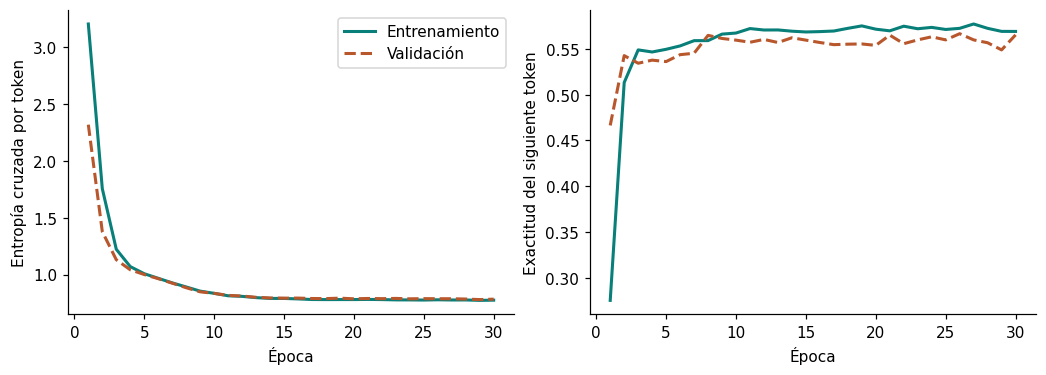

Validación · pérdida 0.784 · exactitud 56.5%


In [6]:
hist_gpt = gpt.fit(
    datos_tf(x_train, y_train, mezclar=True),
    validation_data=datos_tf(x_val, y_val),
    epochs=30, shuffle=False, verbose=0,
).history

def graficar_curva(ax, valores, titulo, color, estilo="-"):
    ax.plot(np.arange(1, len(valores) + 1), valores,
            color=color, linestyle=estilo, label=titulo, linewidth=2)

fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.3), layout="constrained")
for ax, metrica, nombre in zip(axs, ("loss", "exactitud"),
                               ("Entropía cruzada por token", "Exactitud del siguiente token")):
    graficar_curva(ax, hist_gpt[metrica], "Entrenamiento", VERDE)
    graficar_curva(ax, hist_gpt["val_" + metrica], "Validación", NARANJA, "--")
    ax.set(xlabel="Época", ylabel=nombre)
axs[0].legend()
plt.show()
print(f"Validación · pérdida {hist_gpt['val_loss'][-1]:.3f} · exactitud {hist_gpt['val_exactitud'][-1]:.1%}")

El corpus admite varias continuaciones válidas. Por ejemplo, tras «el gato» pueden aparecer **curioso**, **pequeño**, **tranquilo** o **inquieto**. La exactitud se calcula usando el token que aparece en cada frase de validación. Una predicción distinta puede ser gramaticalmente válida. La pérdida evalúa la probabilidad que el modelo asigna al token observado.

### 3.2 Inspeccionar las dos cabezas entrenadas

Extraemos los pesos de la capa de autoatención del mini-GPT sobre una frase de validación. Cada cabeza aprende sus propias proyecciones. En los mapas, cada fila puede repartir peso solamente entre su posición y las anteriores. Usamos la misma escala de color para compararlas.

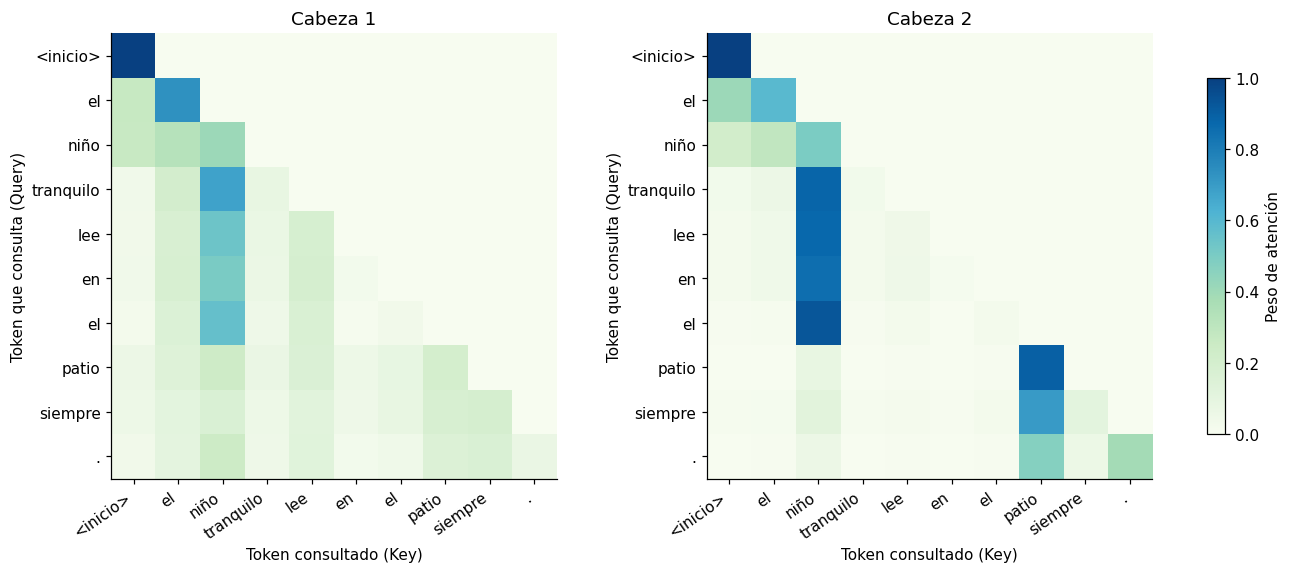

Diferencia máxima entre usar la frase completa y solo su prefijo: 9.54e-07


In [7]:
capa_atencion = gpt.get_layer("autoatencion")
modelo_posiciones = keras.Model(gpt.input, gpt.get_layer("posicion").output)
entrada_demo = x_val[:1]
h_demo = modelo_posiciones(entrada_demo, training=False)
_, mapas = capa_atencion(
    h_demo, h_demo, use_causal_mask=True, return_attention_scores=True, training=False,
)
mapas = mapas.numpy()[0]
etiquetas = [vocabulario[i] for i in entrada_demo[0]]

fig, axs = plt.subplots(1, CABEZAS, figsize=(12, 5.1), layout="constrained")
for i, ax in enumerate(axs):
    mapa = mapa_atencion(ax, mapas[i], etiquetas, f"Cabeza {i + 1}", anotar=False)
fig.colorbar(mapa, ax=axs, shrink=0.8, label="Peso de atención")
plt.show()

futuro = np.triu(np.ones((CONTEXTO, CONTEXTO), dtype=bool), k=1)
assert np.max(np.abs(mapas[:, futuro])) < 1e-6
corte_demo = 4
logits_frase = gpt(entrada_demo, training=False).numpy()[:, :corte_demo]
logits_prefijo = gpt(entrada_demo[:, :corte_demo], training=False).numpy()
diferencia = np.max(np.abs(logits_frase - logits_prefijo))
print(f"Diferencia máxima entre usar la frase completa y solo su prefijo: {diferencia:.2e}")
assert np.allclose(logits_frase, logits_prefijo, atol=1e-5, rtol=1e-5)

### 3.3 Del siguiente token a una frase completa

Escribimos «El gato» y el modelo devuelve un vector de logits para la última posición. Dividimos esos logits por la **temperatura** $T$ antes del *softmax*.

$$
p_j(T)=\operatorname{softmax}(\mathrm{logits}/T)_j.
$$

Con $T=1$ usamos los logits tal como salen del modelo. Al bajar $T$, crece el peso de los candidatos más probables. Al subir $T$, aumenta la probabilidad de candidatos con puntajes menores. La temperatura modifica el muestreo y los pesos del modelo permanecen fijos. Después de elegir un token, lo añadimos al prefijo y volvemos a predecir.

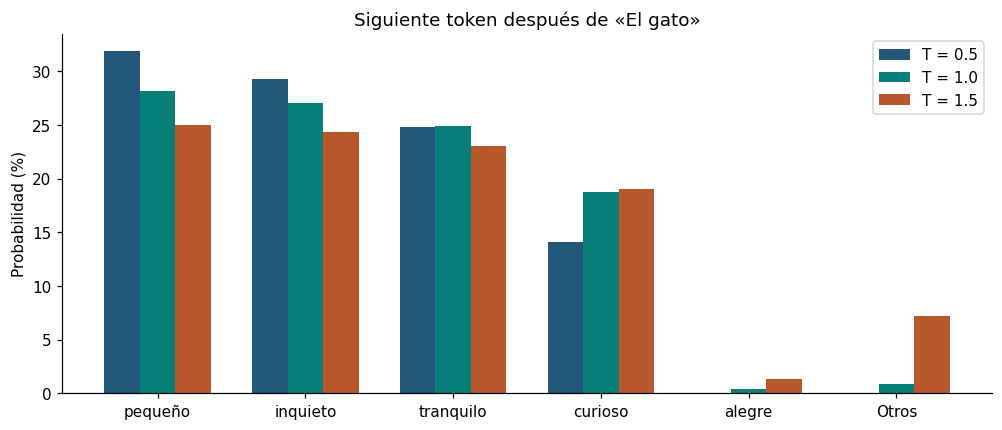

In [8]:
def codificar_prefijo(prefijo):
    tokens = tokenizar(prefijo)
    desconocidos = sorted(set(tokens) - set(token_a_id))
    if desconocidos:
        raise ValueError(f"En este vocabulario no aparecen {desconocidos}")
    secuencia = [token_a_id[INICIO]] + [token_a_id[token] for token in tokens]
    if len(secuencia) > CONTEXTO:
        raise ValueError(f"El prefijo debe caber en {CONTEXTO} posiciones con <inicio>.")
    return secuencia

def logits_siguiente(secuencia):
    entrada = np.asarray([secuencia], dtype=np.int32)
    return gpt(entrada, training=False).numpy()[0, -1]

def probabilidades(logits, temperatura):
    if not np.isfinite(temperatura) or temperatura <= 0:
        raise ValueError("La temperatura debe ser un número positivo y finito.")
    return softmax_filas(logits.astype(np.float64) / temperatura)

PREFIJO = "El gato"
TEMPERATURAS = (0.5, 1.0, 1.5)
COLORES_TEMP = ("#22577a", VERDE, NARANJA)
logits_demo = logits_siguiente(codificar_prefijo(PREFIJO))
top = np.argsort(-logits_demo)[:5]

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
pos = np.arange(len(top) + 1)
for i, (temperatura, color) in enumerate(zip(TEMPERATURAS, COLORES_TEMP)):
    p = probabilidades(logits_demo, temperatura)
    barras = np.r_[p[top], 1 - p[top].sum()]
    ax.bar(pos + (i - 1)*0.24, 100*barras, width=0.24, color=color,
           label=f"T = {temperatura:.1f}")
ax.set(xticks=pos, xticklabels=[vocabulario[i] for i in top] + ["Otros"],
       ylabel="Probabilidad (%)", title=f"Siguiente token después de «{PREFIJO}»")
ax.legend()
plt.show()

In [9]:
def generar(prefijo, temperatura, semilla):
    rng = np.random.default_rng(semilla)
    secuencia = codificar_prefijo(prefijo)
    while len(secuencia) <= CONTEXTO and secuencia[-1] != token_a_id[FIN]:
        p = probabilidades(logits_siguiente(secuencia), temperatura)
        siguiente = int(rng.choice(N_VOCAB, p=p))
        secuencia.append(siguiente)
    tokens = [vocabulario[i] for i in secuencia
              if i not in (token_a_id[INICIO], token_a_id[FIN])]
    return " ".join(tokens).replace(" .", ".").capitalize()

filas = ["| Temperatura | Semilla | Continuación |", "|---:|---:|---|"]
for temperatura in TEMPERATURAS:
    for semilla in (4, 7, 20):
        filas.append(f"| {temperatura:.1f} | {semilla} | {generar(PREFIJO, temperatura, semilla)} |")
display(Markdown("\n".join(filas)))

| Temperatura | Semilla | Continuación |
|---:|---:|---|
| 0.5 | 4 | El gato tranquilo duerme en el sofá hoy. |
| 0.5 | 7 | El gato pequeño juega en el patio temprano. |
| 0.5 | 20 | El gato inquieto duerme en el patio ahora. |
| 1.0 | 4 | El gato tranquilo duerme en el sofá hoy. |
| 1.0 | 7 | El gato pequeño juega en el patio temprano. |
| 1.0 | 20 | El gato inquieto duerme en el patio ahora. |
| 1.5 | 4 | El gato tranquilo duerme en el patio robot silencioso |
| 1.5 | 7 | El gato pequeño juega en el patio temprano. |
| 1.5 | 20 | El gato inquieto duerme en el patio ahora. gato |

## 4. Usar un LLM preentrenado de Hugging Face

En el bloque anterior entrenamos un mini-GPT con una plantilla. Ahora cargaremos **Qwen2.5-0.5B-Instruct**, un Transformer causal de unos **490 millones de parámetros** con soporte para español. Sus pesos ya están entrenados y ajustados para responder a instrucciones. Aquí haremos **inferencia**.

**Primera ejecución.** Necesitas acceso a Hugging Face para descargar cerca de **1 GB**. El modelo es público y reutiliza los pesos descargados en ejecuciones posteriores. Esta sección se puede correr por separado en Jupyter o Colab. Si faltan dependencias, ejecuta `%pip install "torch>=2.4" "transformers>=4.46,<5" matplotlib`. Usamos CPU por defecto. Puedes activar GPU con `USAR_GPU_HF = True` si tienes una disponible con memoria libre.

### 4.1 Cargar el modelo y el tokenizador

In [10]:
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODELO_HF = "Qwen/Qwen2.5-0.5B-Instruct"
USAR_GPU_HF = False

dispositivo_hf = torch.device(
    "cuda" if USAR_GPU_HF and torch.cuda.is_available() else "cpu"
)
dtype_hf = torch.float16 if dispositivo_hf.type == "cuda" else torch.float32

tokenizador_hf = AutoTokenizer.from_pretrained(MODELO_HF)
llm_hf = AutoModelForCausalLM.from_pretrained(
    MODELO_HF, torch_dtype=dtype_hf, use_safetensors=True,
).to(dispositivo_hf).eval()

print(f"Modelo {MODELO_HF} · dispositivo {dispositivo_hf}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo Qwen/Qwen2.5-0.5B-Instruct · dispositivo cpu


### 4.2 Del prompt a las probabilidades

La **plantilla de chat** indica dónde empieza el mensaje del usuario y dónde debe empezar la respuesta del asistente. El tokenizador convierte ese texto en identificadores. Observa las últimas piezas que recibe el modelo. En un tokenizador por subpalabras pueden aparecer fragmentos de palabras, espacios y marcas de rol.

Leemos los logits de la **última posición** y aplicamos *softmax*, igual que en el mini-GPT. La gráfica muestra las cinco opciones con mayor probabilidad para el **primer token de la respuesta**, antes de aplicar temperatura.

Tokens de entrada: 47
Últimos tokens · ID y fragmento del prompt
   662  ' en'
 69888  ' español'
  1709  ' que'
  8486  ' emp'
  9108  'iece'
   390  ' con'
   330  ' "'
  6582  'El'
   342  ' g'
  4330  'ato'
  3263  '".'
151645  [fin de mensaje]
   198  [salto de línea]
151644  [inicio de mensaje]
 77091  'assistant'
   198  [salto de línea]


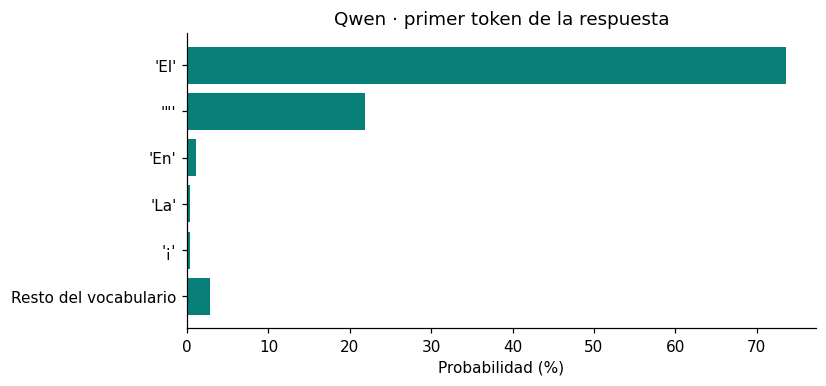

In [13]:
PROMPT_HF = 'Escribe una sola oración breve en español que empiece con "El gato".'

mensajes_hf = [{"role": "user", "content": PROMPT_HF}]
texto_hf = tokenizador_hf.apply_chat_template(
    mensajes_hf, tokenize=False, add_generation_prompt=True,
)
# La plantilla ya contiene los delimitadores especiales del chat.
entrada_hf = tokenizador_hf(
    texto_hf, add_special_tokens=False, return_tensors="pt",
    return_offsets_mapping=True,
)
# Estos rangos sirven para mostrar texto y se retiran antes de llamar al modelo.
rangos_hf = entrada_hf.pop("offset_mapping")[0].tolist()
ids_entrada_hf = entrada_hf["input_ids"][0].tolist()
entrada_hf = entrada_hf.to(dispositivo_hf)

marcas_hf = {
    "<|im_start|>": "[inicio de mensaje]",
    "<|im_end|>": "[fin de mensaje]",
    "\n": "[salto de línea]",
}

print(f"Tokens de entrada: {len(ids_entrada_hf)}")
print("Últimos tokens · ID y fragmento del prompt")
for token_id, (inicio, fin) in zip(ids_entrada_hf[-16:], rangos_hf[-16:]):
    fragmento = texto_hf[inicio:fin]
    etiqueta = marcas_hf.get(fragmento, repr(fragmento) if fragmento else "[sin texto visible]")
    print(f"{token_id:>6}  {etiqueta}")

with torch.inference_mode():
    logits_hf = llm_hf(**entrada_hf).logits[0, -1].float()
    probabilidades_hf = torch.softmax(logits_hf, dim=-1)
    valores_hf, ids_hf = probabilidades_hf.topk(5)

# repr deja visibles espacios y saltos de línea que pueden ser tokens.
etiquetas_hf = [repr(tokenizador_hf.decode([i])) for i in ids_hf.tolist()]
porcentajes_hf = [100 * p for p in valores_hf.tolist()]
porcentajes_hf += [max(0, 100 - sum(porcentajes_hf))]
etiquetas_hf += ["Resto del vocabulario"]

fig, ax = plt.subplots(figsize=(7.4, 3.4), layout="constrained")
ax.barh(list(range(len(etiquetas_hf))), porcentajes_hf, color="#087f79")
ax.set(yticks=list(range(len(etiquetas_hf))), yticklabels=etiquetas_hf,
       xlabel="Probabilidad (%)", title="Qwen · primer token de la respuesta")
ax.invert_yaxis()
plt.show()

### 4.3 Generar la respuesta

`generate` automatiza el ciclo que programamos para el mini-GPT. Selecciona un token, lo incorpora al contexto y repite el proceso. `max_new_tokens` limita cuántos tokens nuevos se pueden producir. La secuencia devuelta contiene el prompt y la respuesta. Conservamos solo los tokens que se añadieron.

In [14]:
TEMPERATURA_HF = 0.7
torch.manual_seed(24)

with torch.inference_mode():
    secuencia_hf = llm_hf.generate(
        **entrada_hf, max_new_tokens=48, do_sample=True,
        temperature=TEMPERATURA_HF, top_k=0, top_p=1.0,
    )

largo_prompt = entrada_hf["input_ids"].shape[1]
ids_respuesta = secuencia_hf[0, largo_prompt:].tolist()
respuesta = tokenizador_hf.decode(ids_respuesta, skip_special_tokens=True)

print("Instrucción")
print(PROMPT_HF)
print("\nRespuesta generada")
print(respuesta)

Instrucción
Escribe una sola oración breve en español que empiece con "El gato".

Respuesta generada
En medio de la tarde, un pequeño gato acariciaba su parrilla mientras dormía en el círculo de su hogar, cautivando la atención de sus vidrios y la joyería.


[Ficha de Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct) · [Plantillas de chat en Hugging Face](https://huggingface.co/docs/transformers/main/en/chat_templating)

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de ChatGPT 6.2 Sol X-High para estructurar el contenido a partir de las diapositivas de la sesión y redactar el texto explicativo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.